Select any suitable dataset from Kaggle.
Perform fine-tuning of a pre-trained deep learning model using your selected dataset.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/Flowers/flower/flowers'

print(os.listdir(path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['sunflower', 'daisy', 'tulip', 'rose', 'dandelion']


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Dataset loading

In [ ]:
import tensorflow as tf

dataset = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/Flowers/flower/flowers',
    image_size=(224, 224),
    batch_size=32,
    label_mode='int',
    shuffle=True,
    seed=42
)

Found 4317 files belonging to 5 classes.


Train and Validation

In [ ]:
total = tf.data.experimental.cardinality(dataset).numpy()

train_dataset = dataset.take(int(total * 0.8))
validation_dataset = dataset.skip(int(total * 0.8))

print("Total Batches:", total)
print("Training Batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation Batches:", tf.data.experimental.cardinality(validation_dataset).numpy())

Total Batches: 135
Training Batches: 108
Validation Batches: 27


VGG16 Model

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(5, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Created Successfully")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model Created Successfully


ModelCheckpoint Callback

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/content/drive/MyDrive/flowers_model.keras',
    save_best_only=True,
    monitor='val_accuracy',
    verbose=1
)

Train

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=[checkpoint]
)

Epoch 1/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5227 - loss: 3.3679
Epoch 1: val_accuracy improved from None to 0.81069, saving model to /content/drive/MyDrive/flowers_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/flowers_model.keras
108/108 ━━━━━━━━━━━━━━━━━━━━ 450s 4s/step - accuracy: 0.6444 - loss: 1.8822 - val_accuracy: 0.8107 - val_loss: 0.5492
Epoch 2/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.7950 - loss: 0.6237
Epoch 2: val_accuracy improved from 0.81069 to 0.83508, saving model to /content/drive/MyDrive/flowers_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/flowers_model.keras
108/108 ━━━━━━━━━━━━━━━━━━━━ 31s 291ms/step - accuracy: 0.7975 - loss: 0.6001 - val_accuracy: 0.8351 - val_loss: 0.4711
Epoch 3/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.8296 - loss: 0.4928
Epoch 3: val_accuracy did not improve from 0.83508
108/108 ━━━━━━━━━━━━━━━━━━━━ 40s 286ms/step - accuracy: 0.8362 - loss:

In [ ]:
best_model = tf.keras.models.load_model(
    '/content/drive/MyDrive/flowers_model.keras'
)

print("Best Model Loaded Successfully")

Best Model Loaded Successfully


Test

In [ ]:
loss, accuracy = best_model.evaluate(validation_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

27/27 ━━━━━━━━━━━━━━━━━━━━ 14s 196ms/step - accuracy: 0.8595 - loss: 0.3821
Validation Loss: 0.38211503624916077
Validation Accuracy: 85.94657182693481 %


Confution Matrix

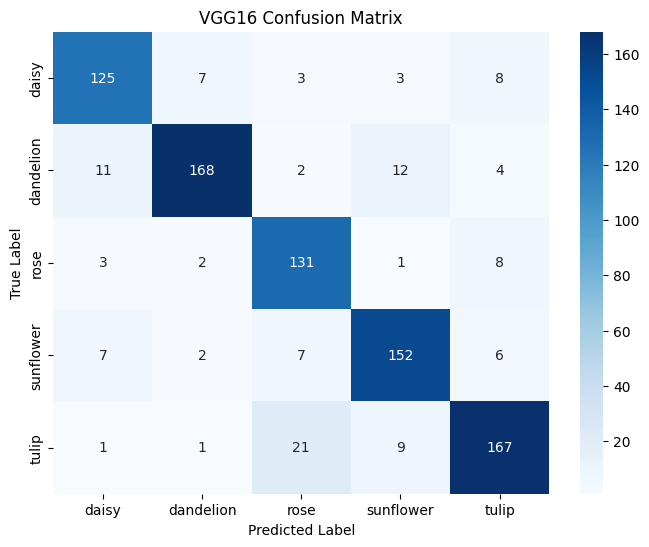

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in validation_dataset:

    predictions = best_model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

class_names = dataset.class_names

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('VGG16 Confusion Matrix')

plt.show()

Classification

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       daisy       0.85      0.86      0.85       146
   dandelion       0.93      0.85      0.89       197
        rose       0.80      0.90      0.85       145
   sunflower       0.86      0.87      0.87       174
       tulip       0.87      0.84      0.85       199

    accuracy                           0.86       861
   macro avg       0.86      0.87      0.86       861
weighted avg       0.87      0.86      0.86       861

